In [7]:
import numpy as np
import torch
import lightning as L

from torch import nn, optim
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision.transforms import Compose, Normalize, Resize, ToTensor, CenterCrop
from torch.utils.data import random_split
from lightning import Trainer
from lightning.pytorch.callbacks import Callback, ModelCheckpoint, EarlyStopping

torch.set_float32_matmul_precision("high")

In [8]:
class FlowerDataModel(L.LightningDataModule):
    def __init__(self, data_dir, batch_size=32, split_ratio=0.8):
        super().__init__()
        self.data_dir = data_dir
        self.batch_size = batch_size
        self.split_ratio = split_ratio

    def setup(self, stage=None):
        transform = Compose([
            Resize(64),
            CenterCrop(64),
            ToTensor(),
            Normalize(mean=[0.4882, 0.4374, 0.3103], std=[0.2832, 0.2543, 0.2812])
        ])
        dataset = ImageFolder(root=self.data_dir, transform=transform)
        train_size = int(self.split_ratio * len(dataset))
        val_size = len(dataset) - train_size
        self.train_dataset, self.val_dataset = random_split(dataset, [train_size, val_size])

    def train_dataloader(self):
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True, num_workers=127)

    def val_dataloader(self):
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False,num_workers=127)

In [9]:
class FlowerClassifier(L.LightningModule):
    def __init__(self, num_classes=5, num_filters=16, dropout_rate=0, learning_rate=3e-4):
        super().__init__()
        self.conv1 = nn.Conv2d(3, num_filters, kernel_size=3)
        self.conv2 = nn.Conv2d(num_filters, num_filters * 2, kernel_size=3)
        self.conv3 = nn.Conv2d(num_filters * 2, num_filters * 4, kernel_size=3)
        self.fc1 = nn.Linear(num_filters * 4 * 6 * 6, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)
        self.drop = nn.Dropout(dropout_rate)
        self.loss_fn = nn.CrossEntropyLoss()
        self.p = dropout_rate
        self.lr = learning_rate

    def featurizer(self, x):
        # First convolutional block
        # 3@64x64 -> n_filters@62x62 -> n_filters@31x31
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        # Second convolutional block
        # n_filters@31x31 -> n_filters@29x29 -> n_filters@14x14
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        # Third convolutional block
        # n_filters@14x14 -> n_filters@12x12 -> n_filters@6x6
        x = self.conv3(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        # Input dimension (n_filters*4@6x6)
        # Output dimension (n_filters * 4 * 6 * 6)
        x = nn.Flatten()(x)
        return x
    
    def classifier(self, x):
        # Input dimension (n_feature * 4 * 6 * 6)
        # Output dimension (128)
        if self.p > 0:
            x = self.drop(x)
        x = self.fc1(x)
        x = F.relu(x)
        # Input dimension (128) -> Output dimension (64)
        if self.p > 0:
            x = self.drop(x)
        x = self.fc2(x)
        x = F.relu(x)
        # Input dimension (64) -> Output dimension (5)
        if self.p > 0:
            x = self.drop(x)
        x = self.fc3(x)
        return x
    
    def forward(self, x):
        x = self.featurizer(x)
        x = self.classifier(x)
        return x
    
    def training_step(self, batch, batch_idx):
        images, labels = batch
        outputs = self(images)
        loss = self.loss_fn(outputs, labels)
        self.log('train_loss', loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss
    
    def validation_step(self, batch, batch_idx):
        images, labels = batch
        outputs = self(images)
        loss = self.loss_fn(outputs, labels)
        acc = (outputs.argmax(dim=1) == labels).float().mean()
        self.log('val_loss', loss, on_step=True, on_epoch=True, prog_bar=True)
        self.log('val_acc', acc, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def configure_optimizers(self):
        return optim.Adam(self.parameters(), lr=self.lr)

In [10]:
class RecordEpochLossCallback(Callback):
    def __init__(self):
        super().__init__()
        self.train_losses = []
        self.val_losses = []

    def on_train_epoch_end(self, trainer, pl_module):
        train_epoch_loss = trainer.callback_metrics.get("train_loss_epoch")
        if train_epoch_loss is not None:
            self.train_losses.append(train_epoch_loss.detach().item())

    def on_validation_epoch_end(self, trainer, pl_module):
        val_epoch_loss = trainer.callback_metrics.get("val_loss_epoch")

        if val_epoch_loss is not None:
            self.val_losses.append(val_epoch_loss.detach().item())

In [11]:
data_dir = "./Datasets/flower_photos"
data_module = FlowerDataModel(data_dir=data_dir, batch_size=64, split_ratio=0.8)
model = FlowerClassifier(num_filters=32, dropout_rate=0.2)
cb = RecordEpochLossCallback()
trainer = Trainer(max_epochs=100, accelerator="auto", 
                  log_every_n_steps=10, callbacks=[cb],
                  strategy="auto", devices="auto")

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [12]:
trainer.fit(model, datamodule=data_module)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ conv1   │ Conv2d           │    896 │ train │     0 │
│ 1 │ conv2   │ Conv2d           │ 18.5 K │ train │     0 │
│ 2 │ conv3   │ Conv2d           │ 73.9 K │ train │     0 │
│ 3 │ fc1     │ Linear           │  589 K │ train │     0 │
│ 4 │ fc2     │ Linear           │  8.3 K │ train │     0 │
│ 5 │ fc3     │ Linear           │    325 │ train │     0 │
│ 6 │ drop    │ Dropout          │      0 │ train │     0 │
│ 7 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 691 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 691 K                                                                                                
Total estimated model params size (MB): 2.767                                                                      
Modules in train mode: 8                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=100` reached.


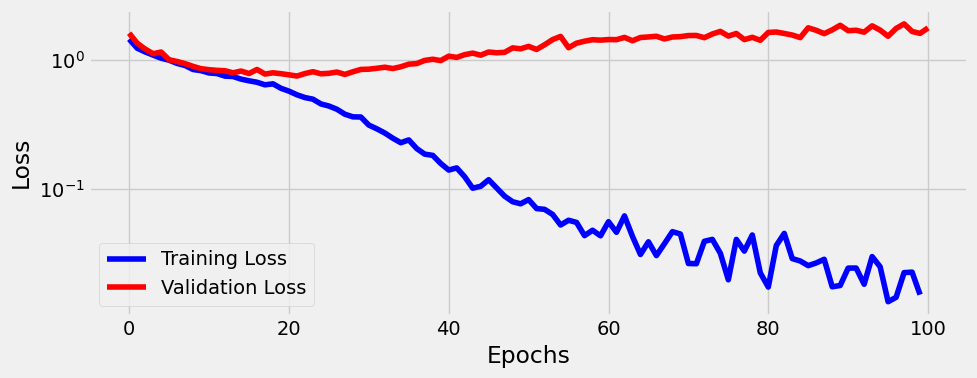

In [13]:
import matplotlib.pyplot as plt
plt.style.use("fivethirtyeight")

def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(cb.train_losses, label="Training Loss", c="b")
    plt.plot(cb.val_losses, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()

In [14]:
# 计算测试集的准确率
import torchmetrics
device = model.device
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=5).to(device)
validation_loader = data_module.val_dataloader()
for x,y in validation_loader:
    x, y = x.to(device), y.to(device)
    outputs = model(x)
    accuracy(outputs, y)
print(f"Test Accuracy: {accuracy.compute().item() * 100:.2f}%")

Test Accuracy: 68.66%
